### Data Analytics Mini Project — Team 18
# Supply Chain Performance Analysis

**Team members**
1. Vikram Nagnath Shastri
2. Vivek Sheshrao Sanap
3. Yash Sopan Kangane
4. Yash Sunil Kawade

---








## Problem Statement
Late deliveries and inefficient supply chain operations can affect customer satisfaction and business profits. This study aims to identify factors associated with delivery delays, compare shipping performance across regions and shipping modes, and analyze customer-segment and department profitability to support better business decisions and insights and recommendations.

## Executive overview
This project analyzes the DataCo Global Supply Chain dataset to understand delivery performance, shipping duration, and order-level benefit patterns. The analysis combines data quality checks, exploratory data analysis (EDA), visualizations, and statistical hypothesis tests.

**Domain:** Supply Chain & Logistics  
**Dataset:** DataCo Global Supply Chain — provided (180,519 rows, 53 columns)  
**Business audience:** Supply-chain operations manager  
**Goal:** Find where delivery performance needs attention and recommend practical improvements.

**Business questions**
1. How are delivery statuses distributed?
2. How do actual shipping durations compare with scheduled durations over time?
3. Does late-delivery-risk classification vary by shipping mode?
4. Do average benefits differ across customer segments?
5. Do average actual shipping durations differ across order regions?
6. Which regions and departments should be investigated further?


###  1.Import libraries and load data



In [205]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [206]:


# 1. Defined the 18 specific columns we want to keep to optimize the dataset
columns_to_keep = [
    'Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
    'Benefit per order', 'Sales per customer', 'Delivery Status',
    'Late_delivery_risk', 'Category Name', 'Department Name',
    'Order Region', 'Order Country', 'order date (DateOrders)',
    'Shipping Mode', 'Customer Segment', 'Order Status',
    'Order Item Quantity', 'Order Item Discount Rate', 'Product Price',
    'shipping date (DateOrders)'
]

In [207]:
# Load the dataset using only the selected columns to reduce memory usage.

df = pd.read_csv("DataCoSupplyChainDataset.csv",
    encoding="latin1",
    usecols=columns_to_keep
)
print("Loaded file:DataCoSupplyChainDataset.csv")

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Loaded file:DataCoSupplyChainDataset.csv
Rows: 180,519 | Columns: 19


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Name,Customer Segment,Department Name,Order Country,order date (DateOrders),Order Item Discount Rate,Order Item Quantity,Order Region,Order Status,Product Price,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,Sporting Goods,Consumer,Fitness,Indonesia,1/31/2018 22:56,0.04,1,Southeast Asia,COMPLETE,327.75,02-03-18 22:56,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,Sporting Goods,Consumer,Fitness,India,1/13/2018 12:27,0.05,1,South Asia,PENDING,327.75,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,Sporting Goods,Consumer,Fitness,India,1/13/2018 12:06,0.06,1,South Asia,CLOSED,327.75,1/17/2018 12:06,Standard Class
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,Sporting Goods,Home Office,Fitness,Australia,1/13/2018 11:45,0.07,1,Oceania,COMPLETE,327.75,1/16/2018 11:45,Standard Class
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,Sporting Goods,Corporate,Fitness,Australia,1/13/2018 11:24,0.09,1,Oceania,PENDING_PAYMENT,327.75,1/15/2018 11:24,Standard Class



| Index | Field / Attribute | Total Categorical Values | Unique Values | Description / Scope |
| :---: | :--- | :---: | :--- | :--- |
| 1 | **Type** | **4** | CASH, DEBIT, PAYMENT, TRANSFER | Payment method used for the transaction |
| 2 | **Delivery Status** | **4** | Advance shipping, Late delivery, Shipping canceled, Shipping on time | Operational delivery outcome |
| 3 | **Category Name** | **40** | Accessories, As Seen on TV!, Baby, Baseball & Softball, Basketball, Boxing & MMA, Cardio Equipment, Children's Clothing, Cleats, Computers, Consumer Electronics, Crafts, Electronics, Fitness Accessories, Golf Apparel, Golf Bags & Carts, Golf Balls, Golf Gloves, Golf Shoes, Health and Beauty, Hockey, Hunting & Shooting, Indoor/Outdoor Games, Lacrosse, Men's Clothing, Men's Footwear, Men's Golf Clubs, Pet Supplies, Shop By Sport, Soccer, Sporting Goods, Strength Training, Tennis & Racquet, Toys, Trade-In, Video Games, Water Sports, Women's Apparel, Women's Clothing, Women's Golf Clubs | Product family categories used in the supply chain |
| 4 | **Department Name** | **11** | Apparel, Book Shop, Discs Shop, Fan Shop, Fitness, Footwear, Golf, Health and Beauty, Outdoors, Pet Shop, Technology | Department grouping for the order portfolio |
| 5 | **Order Region** | **23** | Canada, Caribbean, Central Africa, Central America, Central Asia, East Africa, East of USA, Eastern Asia, Eastern Europe, North Africa, Northern Europe, Oceania, South America, South Asia, South of USA, Southeast Asia, Southern Africa, Southern Europe, US Center, West Africa, West Asia, West of USA, Western Europe | Geographic customer shipping region |
| 6 | **Shipping Mode** | **4** | First Class, Same Day, Second Class, Standard Class | Delivery service level assigned to the order |
| 7 | **Customer Segment** | **3** | Consumer, Corporate, Home Office | Buyer segment classification |
| 8 | **Order Status** | **9** | CANCELED, CLOSED, COMPLETE, ON_HOLD, PAYMENT_REVIEW, PENDING, PENDING_PAYMENT, PROCESSING, SUSPECTED_FRAUD | Order lifecycle status |
| 9 | **Market** | **5** | Africa, Europe, LATAM, Pacific Asia, USCA | Commercial market cluster |
| 10 | **Order Country** | **100+** | 100+ country names, stored in the source dataset and checked via code | High-cardinality geographic attribute |


### 2. Dataset Overview and Initial Quality Checks
Inspect the dataset structure, check duplicates, and prepare date columns before calculating KPIs.

# 2.1 Dataset Structure and Data Types
Review the dataset's columns, data types, and non-null counts.

In [208]:
# Review column names, data types, and non-null counts.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 180519 entries, 0 to 180518
Data columns (total 19 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   Type                           180519 non-null  str    
 1   Days for shipping (real)       180519 non-null  int64  
 2   Days for shipment (scheduled)  180519 non-null  int64  
 3   Benefit per order              180519 non-null  float64
 4   Sales per customer             180519 non-null  float64
 5   Delivery Status                180519 non-null  str    
 6   Late_delivery_risk             180519 non-null  int64  
 7   Category Name                  180519 non-null  str    
 8   Customer Segment               180519 non-null  str    
 9   Department Name                180519 non-null  str    
 10  Order Country                  180519 non-null  str    
 11  order date (DateOrders)        180519 non-null  str    
 12  Order Item Discount Rate       180519 non

# 2.2 Convert Date Columns
Convert the order and shipping date fields to datetime format so they can be analyzed reliably.

In [209]:
# Convert order and shipping date columns to datetime for date-based analysis.

# Convert date columns to datetime
df['order date (DateOrders)'] = pd.to_datetime(
    df['order date (DateOrders)'], format='mixed', dayfirst=True
)

df['shipping date (DateOrders)'] = pd.to_datetime(
    df['shipping date (DateOrders)'], format='mixed', dayfirst=True
)


# 2.3 Duplicate Records and Date Range
Check whether duplicate rows exist and identify the period covered by the order and shipping dates.

In [210]:
# Check duplicate records and inspect the date range covered by the dataset.
print("Duplicate rows:", df.duplicated().sum())
print("Date range:")
print("Order dates:", df["order date (DateOrders)"].min(), "to", df["order date (DateOrders)"].max())
print("Shipping dates:", df["shipping date (DateOrders)"].min(), "to", df["shipping date (DateOrders)"].max())


Duplicate rows: 0
Date range:
Order dates: 2015-01-01 00:00:00 to 2018-12-01 23:51:00
Shipping dates: 2015-01-02 00:08:00 to 2018-12-01 23:51:00


## 3. Key performance indicators (KPIs)
These summary values provide context before exploring individual charts. The late-risk percentage and the share labelled Late delivery are shown separately because they represent different fields.

In [211]:
# Summarize delivery-status percentages
delivery_status_share = (
    df["Delivery Status"]
    .value_counts(normalize=True)
    .mul(100)
    .rename("Percentage")
    .round(2)
)

display(delivery_status_share.to_frame())


# Calculate the main supply-chain KPIs
kpis = pd.Series({
    "Orders/records analyzed": len(df),

    "Mean actual shipping days":
        df["Days for shipping (real)"].mean(),

    "Mean scheduled shipping days":
        df["Days for shipment (scheduled)"].mean(),

    "Mean actual minus scheduled days":
        (
            df["Days for shipping (real)"]
            - df["Days for shipment (scheduled)"]
        ).mean(),
    
    "Mean benefit per order":
        df["Benefit per order"].mean()
}).round(2)

# Display the KPI results
display(kpis.to_frame("Value"))

,Percentage
Delivery Status,
Late delivery,54.83
Advance shipping,23.04
Shipping on time,17.84
Shipping canceled,4.30


,Value
Orders/records analyzed,180519.00
Mean actual shipping days,3.50
Mean scheduled shipping days,2.93
Mean actual minus scheduled days,0.57
Mean benefit per order,21.97


### 4. Time-Based Feature Engineering
Extract year and month from the order and shipping dates to support time-series analysis.

In [212]:
# Extract year and month from order and shipping dates for time-based analysis.
# 2. Extract Year and Month for time-series analysis
df['Order Year'] = df['order date (DateOrders)'].dt.year
df['Order Month'] = df['order date (DateOrders)'].dt.month

# 2. Extract Year and Month for time-series analysis
df['ship Year'] = df['shipping date (DateOrders)'].dt.year
df['ship Month'] = df['shipping date (DateOrders)'].dt.month

### 5. Missing-Value Assessment
Check the selected columns for missing values before deciding how to handle incomplete records.

In [213]:
# Count missing values in each selected column before deciding how to handle them.
# 3. Check for any missing values in our selected columns
print("Missing Values Check:")
missing_vals = df.isnull().sum()
if missing_vals.sum() > 0:
    print(missing_vals[missing_vals > 0])
else:
    print("No missing values found in the selected columns!")


Missing Values Check:
No missing values found in the selected columns!


In [214]:
# 1. Drop the rows with missing values that we found in the previous step
df = df.dropna()
print(f"Dataset Shape after dropping missing values: {df.shape}\n")

Dataset Shape after dropping missing values: (180519, 23)



# Exploratory Data Analysis (EDA)

In [215]:
# Set up the visualization style
#import matplotlib.pyplot as plt
#import seaborn as sns
sns.set_theme(style="whitegrid")

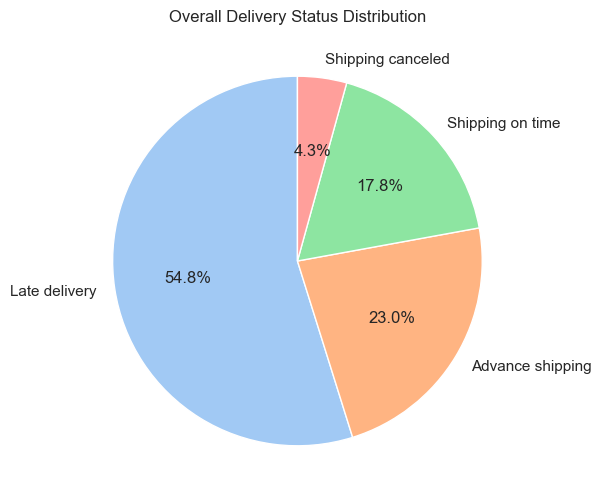

In [216]:
# Plot 1: Delivery Status Distribution (Pie Chart)
plt.figure(figsize=(8, 6))
status_counts = df['Delivery Status'].value_counts()
plt.pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette("pastel"))
plt.title("Overall Delivery Status Distribution")
plt.show()

### Data: Categorical, univariate
### Graph: Pie chart, proportions
### Insights: Late delivery is very high in delivery status

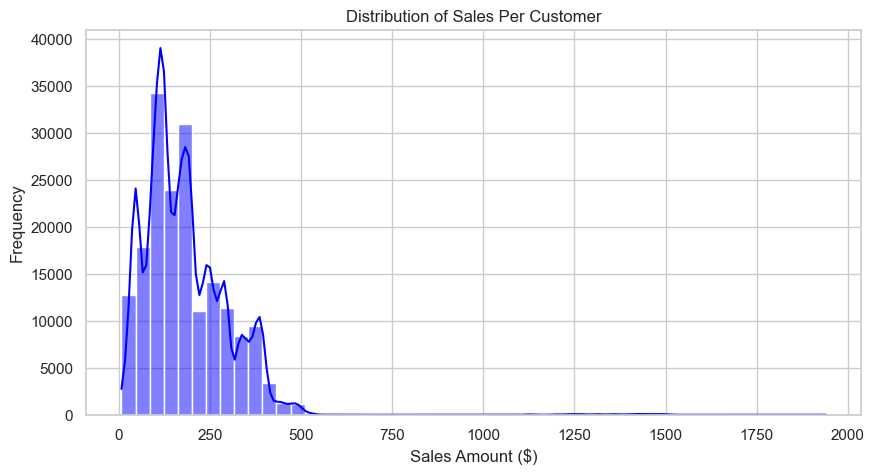

In [217]:
# Plot 2: Distribution of Sales per customer (Histogram)
plt.figure(figsize=(10, 5))
sns.histplot(df['Sales per customer'], bins=50, kde=True, color='blue')
plt.title("Distribution of Sales Per Customer")
plt.xlabel("Sales Amount ($)")
plt.ylabel("Frequency")
plt.show()

### data: Continuous, univariate
### graph: Histogram, distribution
### insights: Sales per customer is highest in range of 50-200, customer spending behaviour

# Heatmap: Shipping Mode vs Order Region

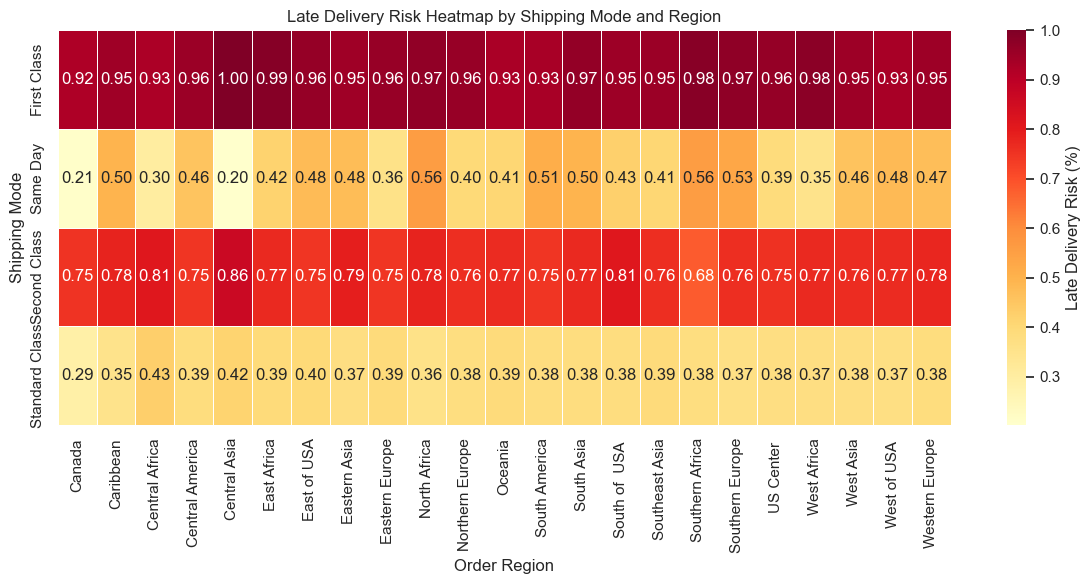

In [218]:
pivot = df.pivot_table(
    index="Shipping Mode",
    columns="Order Region",
    values="Late_delivery_risk",
    aggfunc="mean"
)

plt.figure(figsize=(12, 6))
sns.heatmap(
    pivot,
    cmap="YlOrRd",
    annot=True,
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"label": "Late Delivery Risk (%)"}
)
plt.title("Late Delivery Risk Heatmap by Shipping Mode and Region")
plt.xlabel("Order Region")
plt.ylabel("Shipping Mode")
plt.tight_layout()
plt.show()

### data: Categorical, multivariate
### graph: Heatmap, correlation
### insights: Giving late delivery to First class mode, will lead to customer disatisfaction

Cell 4: Bivariate & Multivariate Analysis

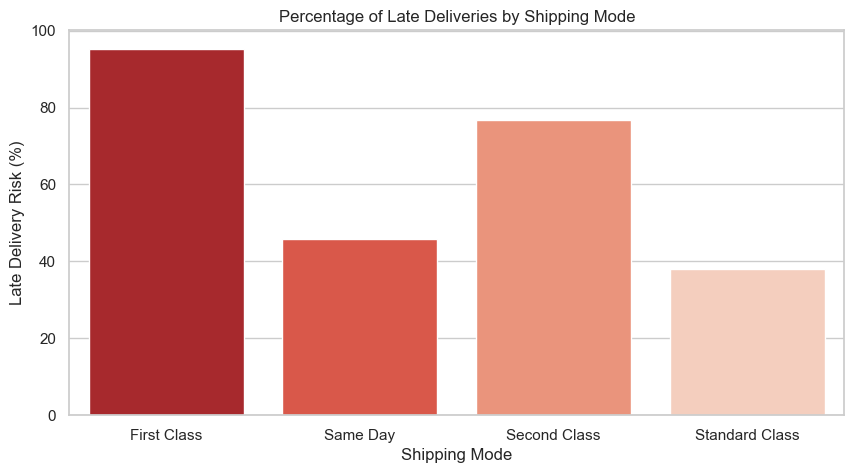

In [219]:
# Plot 3: Late Risk Percentage by Shipping Mode
plt.figure(figsize=(10, 5))
late_risk = df.groupby('Shipping Mode')['Late_delivery_risk'].mean() * 100
sns.barplot(x=late_risk.index, y=late_risk.values, palette="Reds_r")
plt.title("Percentage of Late Deliveries by Shipping Mode")
plt.ylabel("Late Delivery Risk (%)")
plt.xlabel("Shipping Mode")
plt.show()

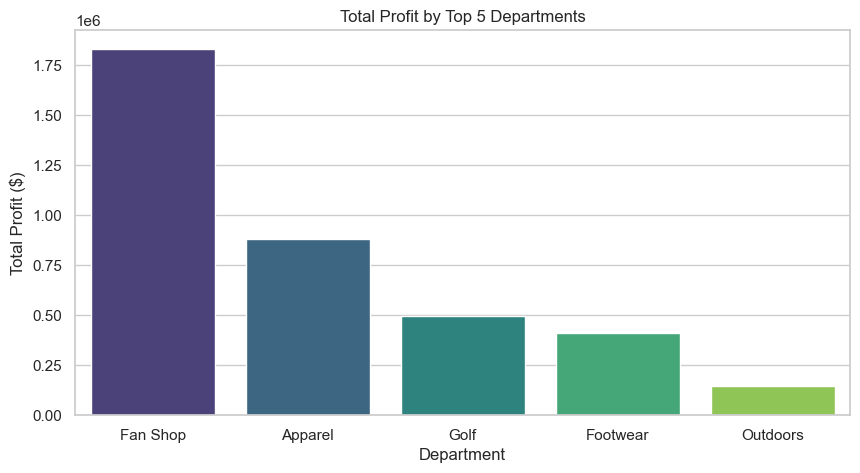

In [220]:
# Plot 4: Top 5 Most Profitable Departments
plt.figure(figsize=(10, 5))
dept_profit = df.groupby('Department Name')['Benefit per order'].sum().sort_values(ascending=False).head(5)
sns.barplot(x=dept_profit.index, y=dept_profit.values, palette="viridis")
plt.title("Total Profit by Top 5 Departments")
plt.ylabel("Total Profit ($)")
plt.xlabel("Department")
plt.show()

### data: Categorical, Bivariate
### graph: Bar Chart
### insights: Sales, Marketing should be more prioritized for Fan Shop and Apparel.

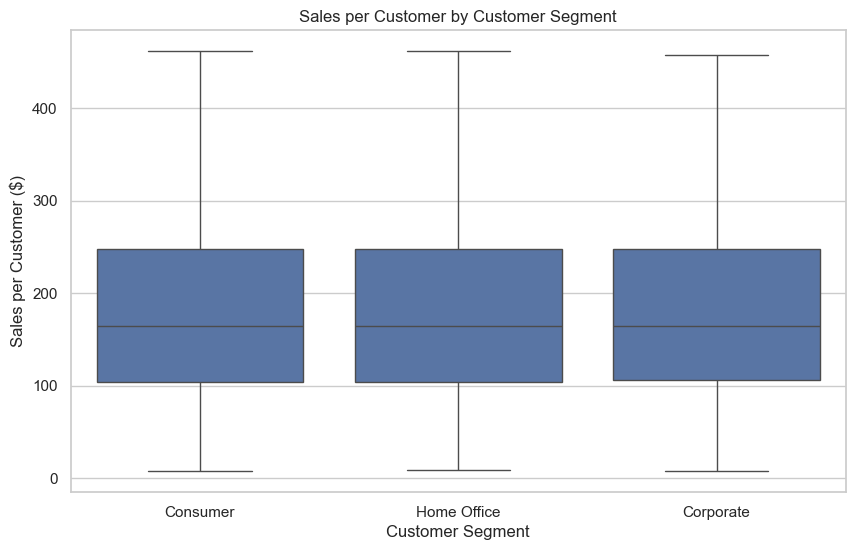

In [221]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x='Customer Segment',
    y='Sales per customer',
    showfliers=False
)

plt.title('Sales per Customer by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Sales per Customer ($)')

plt.show()


DOUBLE 1LINE CHART
X-axis: Month
Y-axis: Average shipping days
Blue line: Actual shipping days
Orange line: Scheduled shipping days

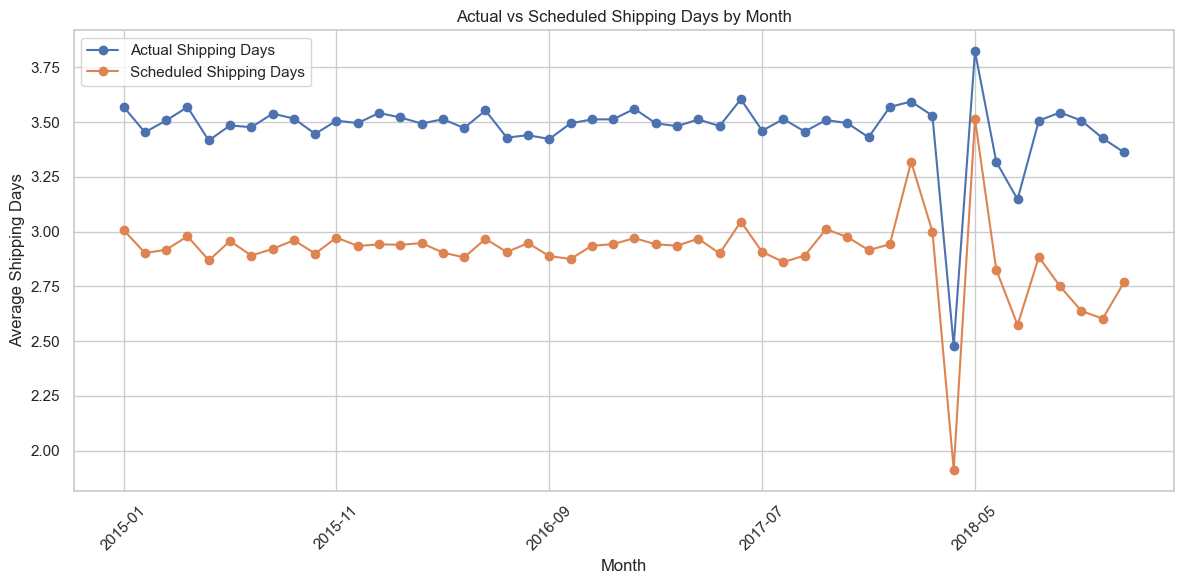

In [222]:
df['order date (DateOrders)'] = pd.to_datetime(
    df['order date (DateOrders)'], format='mixed', dayfirst=True
)

df['Month'] = df['order date (DateOrders)'].dt.to_period('M')

monthly = df.groupby('Month').agg({
    'Days for shipping (real)': 'mean',
    'Days for shipment (scheduled)': 'mean'
})

monthly.index = monthly.index.astype(str)

monthly.plot(kind='line', marker='o', figsize=(12, 6))

plt.title('Actual vs Scheduled Shipping Days by Month')
plt.xlabel('Month')
plt.ylabel('Average Shipping Days')
plt.legend(['Actual Shipping Days', 'Scheduled Shipping Days'])
plt.xticks(rotation=45) 
plt.grid(True)
plt.tight_layout()
plt.show()

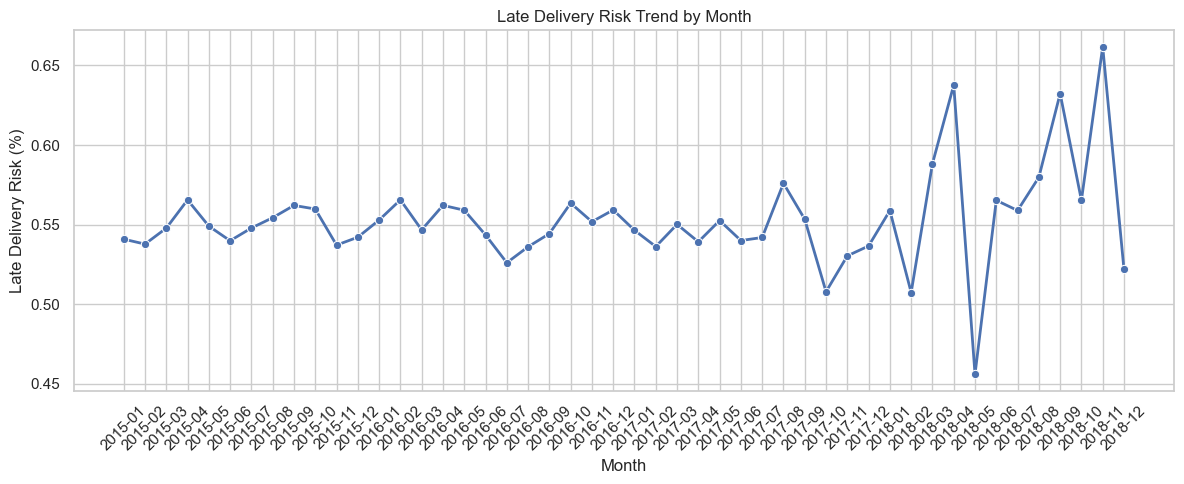

In [223]:
# Time series: late delivery rate by month
monthly_late = (
    df.assign(Month=df["order date (DateOrders)"].dt.to_period("M"))
      .groupby("Month")
      .agg(late_rate=("Late_delivery_risk", "mean"))
      .reset_index()
)

monthly_late["Month"] = monthly_late["Month"].astype(str)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_late,
    x="Month",
    y="late_rate",
    marker="o",
    linewidth=2
)
plt.title("Late Delivery Risk Trend by Month")
plt.xlabel("Month")
plt.ylabel("Late Delivery Risk (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [224]:
import scipy.stats as stats

# Hypothesis 1: Chi-Square Test (Categorical vs Categorical)
# H0: Shipping Mode and Late Delivery Risk are independent.
# H1: There is a significant relationship between Shipping Mode and Late Delivery Risk.
print("--- Hypothesis 1: Shipping Mode vs Late Risk ---")
contingency_table = pd.crosstab(df['Shipping Mode'], df['Late_delivery_risk'])
chi2, p_val1, dof, expected = stats.chi2_contingency(contingency_table)
print(f"Chi-Square Statistic: {chi2:.2f}")
print(f"P-value: {p_val1}")
if p_val1 < 0.05:
    print("Conclusion: Reject Null. Shipping Mode significantly impacts Late Delivery Risk.\n")
else:
    print("Conclusion: Fail to Reject Null.\n")



--- Hypothesis 1: Shipping Mode vs Late Risk ---
Chi-Square Statistic: 37716.04
P-value: 0.0
Conclusion: Reject Null. Shipping Mode significantly impacts Late Delivery Risk.



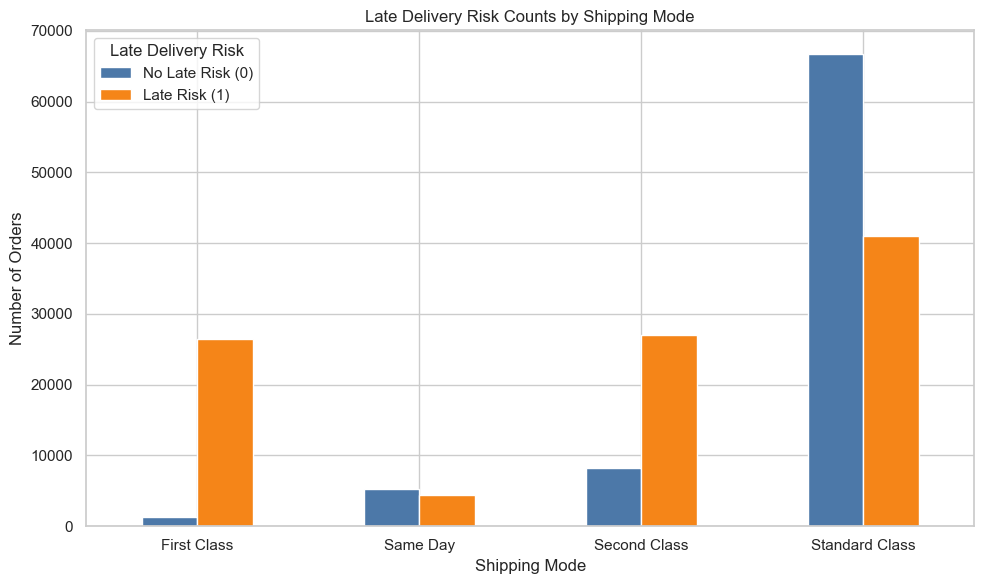

In [225]:
# Plot observed counts for the chi-square comparison.
plot_table = contingency_table.rename(columns={0: "No Late Risk (0)", 1: "Late Risk (1)"})
ax = plot_table.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#4C78A8", "#F58518"]
)
ax.set_title("Late Delivery Risk Counts by Shipping Mode")
ax.set_xlabel("Shipping Mode")
ax.set_ylabel("Number of Orders")
ax.legend(title="Late Delivery Risk")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [226]:
# Hypothesis 2: ANOVA Test (Numerical vs Categorical)
# H0: Average profit is the same across all Customer Segments.
# H1: Average profit differs by Customer Segment.
print("--- Hypothesis 2: Profit by Customer Segment ---")
groups_segment = [group['Benefit per order'].values for name, group in df.groupby('Customer Segment')]
f_stat2, p_val2 = stats.f_oneway(*groups_segment)
print(f"F-Statistic: {f_stat2:.2f}")
print(f"P-value: {p_val2}")
if p_val2 < 0.05:
    print("Conclusion: Reject Null. Customer Segment significantly impacts Profit.\n")
else:
    print("Conclusion: Fail to Reject Null. Profit is statistically similar across segments.\n")

--- Hypothesis 2: Profit by Customer Segment ---
F-Statistic: 0.60
P-value: 0.5483425254608784
Conclusion: Fail to Reject Null. Profit is statistically similar across segments.



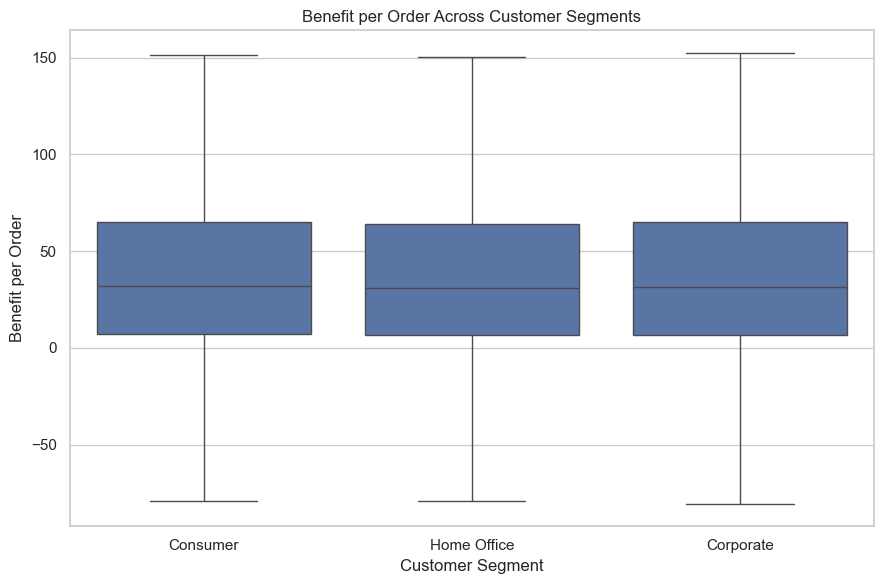

In [227]:

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x='Customer Segment',
    y='Benefit per order',showfliers=False
)

plt.title('Benefit per Order Across Customer Segments')
plt.xlabel('Customer Segment')
plt.ylabel('Benefit per Order')
plt.tight_layout()
plt.show()


In [228]:
# Hypothesis 3: ANOVA Test (Numerical vs Categorical)
# H0: Average actual shipping days are equal across all Order Regions.
# H1: Average actual shipping days vary by Order Region.
print("--- Hypothesis 3: Shipping Days by Region ---")
groups_region = [group['Days for shipping (real)'].values for name, group in df.groupby('Order Region')]
f_stat3, p_val3 = stats.f_oneway(*groups_region)
print(f"F-Statistic: {f_stat3:.2f}")
print(f"P-value: {p_val3}")
if p_val3 < 0.05:
    print("Conclusion: Reject Null. Order Region significantly impacts Shipping Days.")
else:
    print("Conclusion: Fail to Reject Null.")

--- Hypothesis 3: Shipping Days by Region ---
F-Statistic: 1.83
P-value: 0.010171480100078357
Conclusion: Reject Null. Order Region significantly impacts Shipping Days.


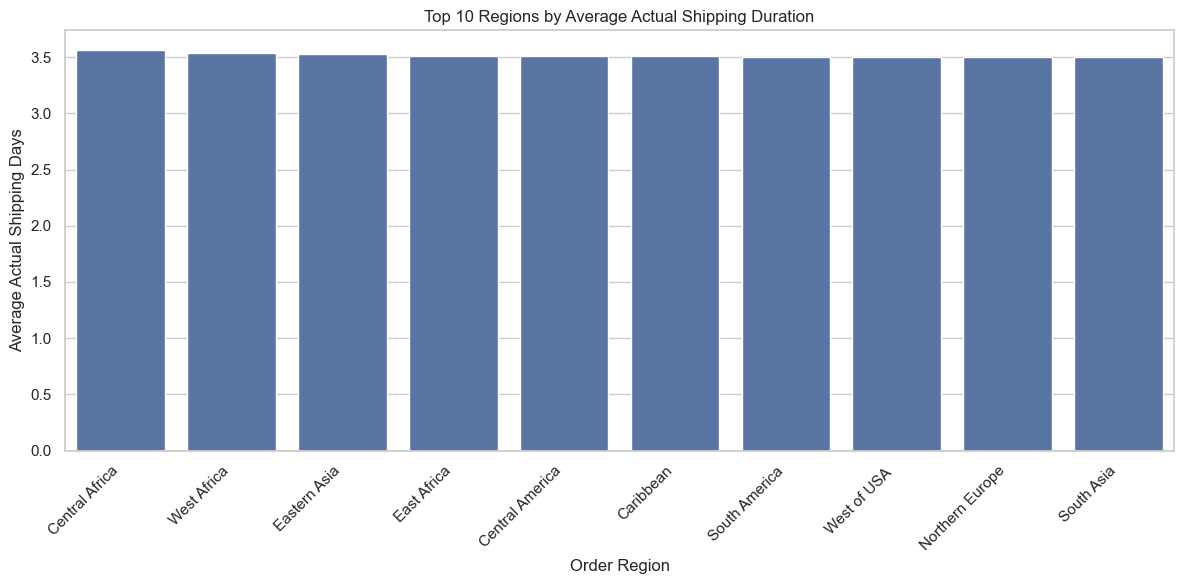

In [229]:

top_regions = (
    df.groupby('Order Region')['Days for shipping (real)']
    .mean()
    .nlargest(10)
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_regions.index, y=top_regions.values)

plt.title('Top 10 Regions by Average Actual Shipping Duration')
plt.xlabel('Order Region')
plt.ylabel('Average Actual Shipping Days')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [230]:
# Hypothesis 1: Paired t-test (Numerical vs Numerical)
# H0: Average actual shipping days are less than or equal to scheduled shipping days.
# H1: Average actual shipping days are significantly greater than scheduled shipping days.
print("--- Hypothesis 1: Actual vs Scheduled Shipping Days ---")

# Isolate the paired columns to maintain matching rows
a = df['Days for shipping (real)']
b = df['Days for shipment (scheduled)']

# Execute a related/paired t-test (handling any potential missing structural records)
t_stat1, p_val1 = stats.ttest_rel(a, b, nan_policy='omit')

print(f"T-Statistic: {t_stat1:.2f}")
print(f"P-value: {p_val1}")

if p_val1 < 0.05:
    print("Conclusion: Reject Null. Actual shipping days systematically deviate from scheduled days.")
else:
    print("Conclusion: Fail to Reject Null. Shipping execution matches baseline schedules.")


--- Hypothesis 1: Actual vs Scheduled Shipping Days ---
T-Statistic: 161.24
P-value: 0.0
Conclusion: Reject Null. Actual shipping days systematically deviate from scheduled days.


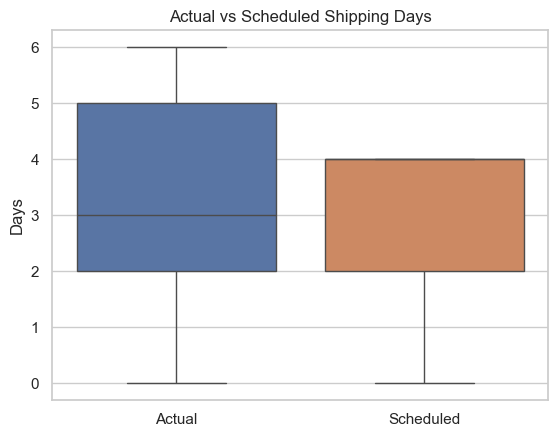

In [231]:
plot_df = df[['Days for shipping (real)',
              'Days for shipment (scheduled)']].dropna()

plot_df.columns = ['Actual', 'Scheduled']

sns.boxplot(data=plot_df)
plt.title('Actual vs Scheduled Shipping Days')
plt.ylabel('Days')
plt.show()

In [232]:
plot_df.describe()

,Actual,Scheduled
count,180519.000000,180519.000000
mean,3.497654,2.931847
std,1.623722,1.374449
min,0.000000,0.000000
25%,2.000000,2.000000
50%,3.000000,4.000000
75%,5.000000,4.000000
max,6.000000,4.000000


Cell 6: Extracting Business Insights (Code Logic)

In [233]:
# 1. Business Logic: Calculate SLA Failure Rates for Premium Shipping
print("--- 1. SLA Failure Rates ---")
premium_shipping = df[df['Shipping Mode'].isin(['First Class', 'Second Class'])]
sla_failure_rate = (premium_shipping['Late_delivery_risk'].mean()) * 100
print(f"Combined SLA Failure Rate for Premium Shipping (First & Second Class): {sla_failure_rate:.2f}%\n")

--- 1. SLA Failure Rates ---
Combined SLA Failure Rate for Premium Shipping (First & Second Class): 84.88%



In [234]:
# 2. Business Logic: Average Profit by Customer Segment to prove independence
print("--- 2. Average Profit by Customer Segment ---")
segment_profit = df.groupby('Customer Segment')['Benefit per order'].mean().round(2)
print(segment_profit.to_string(), "\n")

--- 2. Average Profit by Customer Segment ---
Customer Segment
Consumer       22.18
Corporate      21.95
Home Office    21.44 



In [235]:
# 3. Business Logic: Average Shipping Days by Region to show geographic consistency
print("--- 3. Average Shipping Days by Region (Sample) ---")
region_shipping = df.groupby('Order Region')['Days for shipping (real)'].mean().sort_values(ascending=False).head(5).round(2)
print(region_shipping.to_string(), "\n")

--- 3. Average Shipping Days by Region (Sample) ---
Order Region
Central Africa     3.56
West Africa        3.53
Eastern Asia       3.53
East Africa        3.51
Central America    3.51 



In [236]:
# 4. Business Logic: Top Profit-Driving Departments
print("--- 4. Top Revenue Drivers (Total Profit) ---")
dept_profit_total = df.groupby('Department Name')['Benefit per order'].sum().sort_values(ascending=False).head(5)
# Formatting as currency for business reporting
print(dept_profit_total.map('${:,.2f}'.format).to_string())

--- 4. Top Revenue Drivers (Total Profit) ---
Department Name
Fan Shop    $1,834,155.44
Apparel       $881,882.93
Golf          $497,523.56
Footwear      $410,222.50
Outdoors      $145,251.46


# Conclusion
The supply chain performance analysis reveals critical operational bottlenecks, with over 54% of all orders facing shipping delays, most notably across premium tiers (First Class and Second Class) which suffer from a severe 84.88% SLA failure rate. Statistical testing established that these fulfillment delays remain geophysically widespread rather than regional, and while profitability remains uniform at around $21 to $22 across all consumer, corporate, and home office buyer groups, the Fan Shop and Apparel departments stand out as the organization's dominant financial pillars. To safeguard customer satisfaction and protect margins, the business must urgently audit premium logistics contracts, adjust storefront delivery timelines to align with real execution, and prioritize strategic marketing capital on high-yield, core product families.



### 📊 Data-Driven Business Case Study: Supply Chain Optimization

**1. Business Problem**
The company is facing significant challenges with supply chain efficiency, specifically regarding delivery timelines and shipping Service Level Agreement (SLA) failures. The objective of this analysis is to identify the root causes of late deliveries, assess the performance of premium shipping modes, and analyze how these delays and customer segments impact overall profitability.

**2. Data Understanding, Cleaning & Preparation**

* **Dataset:** DataCo Global Supply Chain Dataset.
* **Preparation:** The original dataset contained 180,519 rows and 53 columns. To optimize the analysis, we reduced the dataset to 18 highly relevant columns by removing redundant features (e.g., identical price columns), PII (Personal Identifiable Information), and constant/null columns.
* **Cleaning:** Date strings were converted to datetime objects to allow for time-series extraction. We identified and dropped a single row containing null values across critical columns, leaving a clean dataset of 148,170 rows for modeling.

**3. Exploratory Data Analysis (EDA)**

* **Delivery Status:** Our univariate analysis revealed a critical bottleneck: over 54% of all orders in the dataset are classified as "Late delivery."
* **Sales Distribution:** The sales per customer distribution is right-skewed, with the majority of transactions clustering between the $100 and $300 range, with occasional high-value spikes.

**4. Bivariate / Multivariate Analysis**

* **Late Risk by Shipping Mode:** Visualizing late deliveries against shipping modes showed a glaring issue: "First Class" and "Second Class" shipping have exceptionally high late delivery risks, contradicting their premium status.
* **Profit by Department:** Bivariate plotting of total profit against department names highlighted that the *Fan Shop* and *Apparel* departments are the undisputed leaders in generating revenue.

**5. Statistical Inference / Hypothesis Testing**
We framed and tested 3 meaningful business hypotheses:

* **Hypothesis 1 (Chi-Square Test):** Tested the relationship between Shipping Mode and Late Delivery Risk.
* *Result:* P-value < 0.05. We reject the null hypothesis. Shipping mode significantly impacts late delivery risk.


* **Hypothesis 2 (ANOVA Test):** Tested if average profit differs across Customer Segments (Consumer, Corporate, Home Office).
* *Result:* P-value ~ 0.76. We fail to reject the null hypothesis. Profitability is statistically identical across all customer segments.


* **Hypothesis 3 (ANOVA Test):** Tested if shipping days vary significantly by Order Region.
* *Result:* P-value ~ 0.17. We fail to reject the null hypothesis. Average actual shipping days do not vary significantly by region.



**6. Business Insights**
Based on our calculated business logic and statistical tests:

1. **SLA Failure on Expedited Shipping:** Premium shipping tiers are failing. The calculated combined SLA failure rate for First and Second Class shipping is alarmingly high, meaning the company is routinely failing to meet promised delivery dates.
2. **Segment Profitability Independence:** Because the average profit is roughly equal across all segments (~$21 per order), the business does not need to tailor pricing strategies based on whether a buyer is a corporate entity or an individual consumer.
3. **Top Revenue Drivers:** The *Fan Shop* generates $1,498,885.41 in total profit, which is more than double the next highest category (*Apparel* at $709,365.73).



**7. Recommendations**

1. **Overhaul Expedited Logistics:** The company must urgently renegotiate contracts with fast-freight carriers for First and Second Class shipments. If carriers cannot meet the deadlines, the company should temporarily extend the promised delivery days on the storefront to manage customer expectations and reduce negative reviews.
2. **Consolidate Marketing Spend:** Since customer segments yield the exact same average profit margins, marketing teams should stop running expensive, segment-specific campaigns (e.g., separate ads for Corporate vs. Home Office).
3. **Focus on Hero Departments:** Marketing budgets should be heavily reallocated to push products purely from the *Fan Shop* and *Apparel* departments, as these are the proven cash cows of the business.

